In [ ]:
import os
import sys

import joblib
import itertools
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.helper_functions import load_outlier_data
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.dbscan_detector import DBSCANDetector
from utils.metrics import movement_level_confusion
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Park'
ALGORITHM_NAME = 'DBSCAN'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [3]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)

In [4]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
GT L: 1 positivos / 185 movimentos = 0.54%
GT R: 3 positivos / 185 movimentos = 1.62%
GT OR: 4 positivos / 185 movimentos = 2.16%


In [5]:
# group_array = [
#     'xs_L', 'ys_L', 'zs_L', 'xe_L', 'ye_L', 'ze_L', 'xw_L', 'yw_L', 'zw_L', # Braço Esquerdo
#     'xs_R', 'ys_R', 'zs_R', 'xe_R', 'ye_R', 'ze_R', 'xw_R', 'yw_R', 'zw_R'  # Braço Direito
# ]
group_array = [
    'x_L', 'y_L', 'z_L', # Left Arm
    'x_R', 'y_R', 'z_R' # Right Arm
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 185/185 [00:00<00:00, 1974.98it/s]

Shape of first series: (46, 6)


Shape of formatted series: (185, 466, 6)


# DBSCAN 
O DBSCAN não sabe o que é o DTW, somente distâncias numéricas. Então, para fazer o DBSCAN tenho de lhe passar uma matriz de distâncias já calculadas.plot_movement_data

In [6]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

# Ground truth used for evalution on this run
GT_KEY = 'OR'  # TODO isto vai ter de ficar noutro local, mas por agora é só para testar
gt_used = GT[GT_KEY]
total_known_outliers = len(gt_used)

# Movement-level anomalies
known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
known_percentage = known_outlier_rate * 100

# Sincronization: series matrix (X_movement) and DTW matrix must have the same number of rows as the metadata
if X_movement.shape[0] != n_movements:
    raise ValueError(f"X_movement ({X_movement.shape[0]}) != metadata ({n_movements})")
# if dtw_matrix.shape[0] != n_movements:
    # raise ValueError(f"DTW ({dtw_matrix.shape[0]}) != metadata ({n_movements})")


# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")
print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")

Phase: Park
positives by ground truth: {'L': 1, 'R': 3, 'OR': 4}
GT used (Union): 4 positives / 185 movements = 2.16%


## Grid Search

### Calculate Kneedle for each fold

In [7]:
unique_subjects = results_temp_base['sub'].unique()
min_samples_range = [3, 4, 5, 7, 10]

fold_param_grids = {}

def make_dbscan_grid_fn(metric='precomputed', k=4, rel_width=0.15, n_eps=20,
                        min_samples_range=(3, 4, 5, 7, 10)):
    def grid_fn(X_train):
        nbrs = NearestNeighbors(n_neighbors=k, metric=metric).fit(X_train)
        distances, _ = nbrs.kneighbors(X_train)
        k_dist = np.sort(distances[:, k - 1])

        knee = KneeLocator(range(len(k_dist)), k_dist, curve='convex', direction='increasing')
        eps0 = knee.elbow_y
        if eps0 is None:                        # No knee found, fallback to mean
            print("⚠️ Kneedle sem cotovelo, fallback para a média")
            eps0 = float(np.mean(k_dist))

        # Generate a range of eps values around the knee point
        eps_range = np.unique(np.round(np.linspace(eps0 * (1 - rel_width), eps0 * (1 + rel_width), n_eps), 4))
        return [{'eps': float(e), 'min_samples': m}
                for e, m in itertools.product(eps_range, min_samples_range)]
    return grid_fn

In [9]:
matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.late_fusion_dtw_matrix_path)

loso_results = run_loso_evaluation(
    detector_class=DBSCANDetector, 
    param_grid=make_dbscan_grid_fn(metric='precomputed'),
    data_matrix=matrices[0.5], # TODO placeholder, replaced per fold
    metadata_df=results_temp_base,
    known_outliers_df=gt_used,
    metric_type='precomputed',
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    dtw_matrices=matrices
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

print("\nSearch Results:")
print("Teste", f"MCC={loso_results['MCC']:.3f}", f"Rej={loso_results['Rejection_Rate']:.1f}%",
          f"AUROC={loso_results['AUROC']:.3f}")

LOSO Cross-Validation with 19 subjects (4 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.298 Rej=11.4% AUROC=nan


### Statistic Evaluation - Bootstraping

In [10]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [11]:
append_experiment_record(
    summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, GT_KEY),
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=n_movements,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for DBSCAN - ShapeBased - Park - 185 Movements (MOVEMENT-level):
Unique Outliers Detected: 21
Rejection Rate: 11.35%
Known Positives in Ground Truth: 4
------------------------------
Total True Positives (Global):  3
Total False Positives (Global): 18
Total False Negatives (Global): 1
Total True Negatives (Global):  163
------------------------------
Blind Precision: 14.29 [4.43–50.00]
Blind Recall:    75.00 [20.00–100.00]
Blind F1-Score:  24.00
Blind F2-Score:  40.54 [14.63–76.92]
Blind MCC:       0.30 [0.08–0.67]
Blind AUPRC:     N/A (detector has no continuous score_blind, or no known positives)
Blind AUROC:     N/A

Total Tuning Time (19 Subjects): 7.5967s
Total Inference Time (19 Subjects): 0.0223s

Overall Best Parameters (Most frequent across folds):
   {'eps': 1685.3227, 'min_samples': 3}
Occurrences: 12


## Treinar Modelo Final

In [12]:
best_params = loso_results['Best_Params']
best_eps = best_params['eps']
best_min_samples = best_params['min_samples']

selected_radius = loso_results['Most_Frequent_DTW_Radius']
selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

In [13]:
dbscan_model = DBSCAN(eps=best_eps,min_samples=best_min_samples, metric='precomputed')
labels = dbscan_model.fit_predict(selected_dtw_matrix)
joblib.dump(dbscan_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))


outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)

In [14]:
# Reconstruct matadata to join with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0) # shape (n_samples - n_outliers, T, n_features)
X_movement_outliers = X_movement[outlier_indices] # shape (n_outliers, T, n_features)

print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Trash Percentage (sub + repID + movID): {(n_outliers/len(selected_dtw_matrix)*100):.2f}%") # instead of total_trials, I can use len(dtw_matrix)
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 5
Unique Outlier Trials Detected: 5
Detected Trash Percentage (sub + repID + movID): 2.70%
Detected Outlier Percentage (sub + repID): 5.26%


In [15]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Outlier Details:")
print(real_outliers_info)

Outlier Details:
     sub  repID  movID movLabel
1      1      2      9     Park
2      1      3      9     Park
46    10      2      9     Park
90    15      2     10     Park
146   18      1     10     Park


In [ ]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = movement_level_confusion(metadata_df, outlier_indices, gt_used, Configs.KEYS)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 3
False Positives (Identified, not in CSV): 2
False Negatives (In CSV, not identified): 1
True Negatives (Normal, stayed normal): 89
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
0   16      2

Precision (False Positives): 3/5 (60.00%)
Recall (True Positive Rate): 3/4 (75.00%)
F1-Score: 66.67%
F2-Score: 71.43%


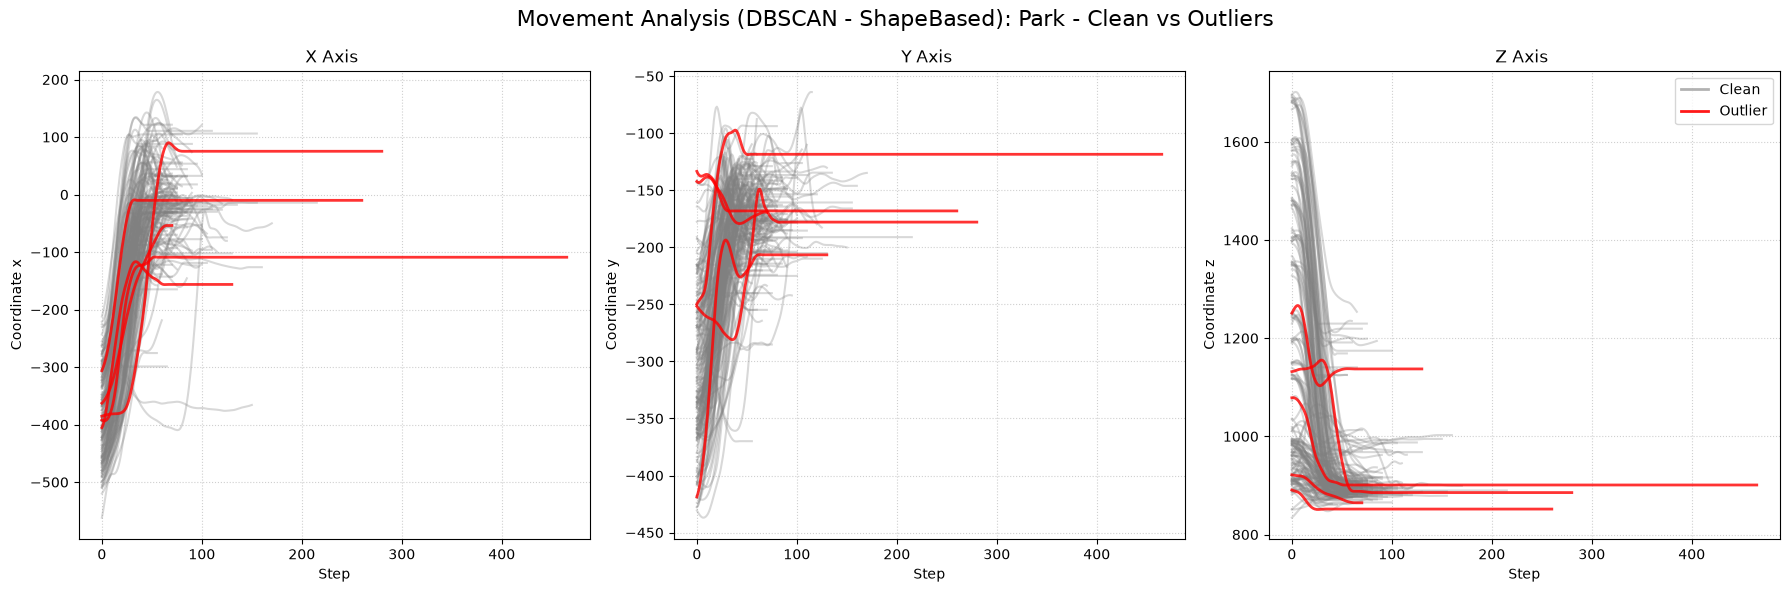

In [17]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)